# 02 – Bee Haven: Datenqualität (N2)

**Ziel:** Fachlich unplausible Werte eines Standorts (`STADT`) markieren und flow in Ausflug/Einflug trennen; Ergebnis mit UTC-Zeitstempel nach `silver/cleaned` speichern.

**Regeln (Pflichtenheft PH-ITS-002, Kap. 2.2 und Schritt 5.9a) – Grenzen und Zeiträume je Stadt aus der Konfiguration:**
- R5 weight unter der Mindestgrenze → ungültig (`konfiguration/sensoren.csv`, heute 20 kg für beide Städte)
- R5a bekannte Ausfallzeiträume → ungültig (`konfiguration/ausschluesse.csv`, heute nur Schwartau 28.04.–02.07.2018 „Stock nicht auf Waage“, E5)
- R6 humidity außerhalb 0–100 % → ungültig
- R7a temperature außerhalb −40 … 60 °C → ungültig (physikalisch unmöglich, z. B. Fehlerwerte bis −227 °C)
- R7 temperature unter 0 °C, aber im gültigen Bereich → behalten und als Frost kennzeichnen
- R8 flow in 2 Spalten trennen (Ausflug/Einflug)
- R9 Ausreißer (robuster z-Score) markieren

**Grundsatz:** markieren statt löschen – ungültige Werte werden leer (NaN), die Spalte `qualitaet` nennt den Grund; statistische Ausreißer (R9) bekommen eine eigene Spalte `<messwert>_auffaellig` und behalten ihren Wert. **Neue Stadt = neue Zeilen in der Konfiguration, kein neuer Code.**

**Ergebnistexte:** gelten für jeden Standort; die Zahlen stehen in der Ausgabe. „Kontrollwerte“ = erwartete Werte je Stadt (Stand 02.10.2026).

## 0. Bibliotheken und Pfade

**Kontrollwert:** keine Ausgabe, keine Fehlermeldung

In [1]:
# --- Parameter: Standort (neue Stadt = Zeile in lakehouse/konfiguration/standorte.csv + Ordner in silver/processing) ---
STADT = "schwartau"                                       # Standort = Unterordner in bronze/silver/gold und Teil der Dateinamen

# --- Bibliotheken laden ---
import pandas as pd                      # pandas: Tabellen einlesen, prüfen, speichern
from pathlib import Path                 # Path: Ordner- und Dateipfade angeben
from datetime import datetime, timezone  # für den UTC-Zeitstempel im Dateinamen

# --- Pfade festlegen ---
PROJEKT = Path.cwd().parent                                    # Projektordner = eine Ebene über 03_notebooks_ITS-Data
ZWISCHENSTAND = PROJEKT / "02_daten_ITS-Data" / "zwischenstand"         # Eingang: Ergebnis aus N1
CLEANED = PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "silver" / "cleaned" / STADT  # Ausgang: bereinigte Daten
BILDER = PROJEKT / "04_images" / STADT                                   # Grafiken je Stadt (04_images/<stadt>/)
sensoren = ["flow", "humidity", "temperature", "weight"]       # Liste der Sensoren

# --- Standortdaten aus der Konfiguration (Koordinaten, Zeitzone) ---
standorte = pd.read_csv(PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "konfiguration" / "standorte.csv", index_col="stadt")
if STADT not in standorte.index:                          # unbekannte Stadt -> sofort abbrechen statt mit falschen Daten weiterrechnen
    raise ValueError(f"Standort '{STADT}' fehlt in konfiguration/standorte.csv – Zeile mit Koordinaten und Zeitzone ergänzen")
ORT = standorte.loc[STADT]                                # eine Zeile: name, breite, laenge, zeitzone, quelle

# --- Sensor-Regeln je Standort (Einheit der Rohdaten, gültiger Bereich) und bekannte Ausfallzeiträume ---
KONFIG = PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "konfiguration"                  # Ordner mit den Konfigurationstabellen
sensoren_cfg = pd.read_csv(KONFIG / "sensoren.csv")                                    # eine Zeile je Stadt und Sensor
REGELN = sensoren_cfg[sensoren_cfg["stadt"] == STADT].set_index("sensor")              # Regeln dieser Stadt: einheit_roh, min, max
ausschluesse = pd.read_csv(KONFIG / "ausschluesse.csv")                                # bekannte Ausfallzeiträume (z. B. Stock nicht auf Waage)
AUSSCHLUESSE = ausschluesse[ausschluesse["stadt"] == STADT].copy()                     # nur Zeiträume dieser Stadt
AUSSCHLUESSE[["von_utc", "bis_utc"]] = AUSSCHLUESSE[["von_utc", "bis_utc"]].apply(pd.to_datetime, utc=True)  # Text -> UTC-Zeit
ZEITZONE = ORT["zeitzone"]                                # Ortszeit der Rohdaten (Deutschland: Europe/Berlin)

**Ergebnis:**

Bibliotheken und Pfade ohne Fehler geladen.

## 1. Import der N1-Ergebnisse

**Kontrollwert:** 4 Tabellen mit den Spalten `timestamp`, Messwert, `zeit_utc` (Typ UTC-Zeit); Zeilenzahl wie in N1 (Kapitel 1 dort)

In [2]:
# --- N1-Ergebnisse (Parquet) einlesen ---
n1 = {}                                                                   # leeres Dictionary: Sensor -> Tabelle
for s in sensoren:                                                        # für jeden Sensor ...
    n1[s] = pd.read_parquet(ZWISCHENSTAND / f"{s}_{STADT}_n1.parquet")  # ... Zwischenstand aus N1 laden
    print(f"{s:12} {len(n1[s]):>10,} Zeilen  {dict(n1[s].dtypes.astype(str))}")  # ... Zeilen + Datentypen prüfen

flow          2,513,836 Zeilen  {'timestamp': 'str', 'flow': 'int64', 'zeit_utc': 'datetime64[us, UTC]'}
humidity          1,761 Zeilen  {'timestamp': 'str', 'humidity': 'float64', 'zeit_utc': 'datetime64[us, UTC]'}
temperature     253,430 Zeilen  {'timestamp': 'str', 'temperature': 'float64', 'zeit_utc': 'datetime64[us, UTC]'}
weight            1,761 Zeilen  {'timestamp': 'str', 'weight': 'float64', 'zeit_utc': 'datetime64[us, UTC]'}


**Ergebnis:** Zeilenzahlen wie in N1; `zeit_utc` ist weiterhin `datetime64[us, UTC]` → Parquet hat die Datentypen behalten.

| Kontrollwerte | flow · humidity · temperature · weight (Zeilen) |
| :-- | :-- |
| Schwartau | 2.513.836 · 1.761 · 253.430 · 1.761 |
| Würzburg | 2.055.520 · 20.845 · 958.831 · 1.035.861 |

## 2. Arbeitskopien erstellen

**Kontrollwert:** je Sensor eine Kopie mit neuer Spalte `qualitaet` („ok“ bzw. „fehlend“)

In [3]:
# --- Arbeitskopien: N1-Stand bleibt zum Vergleich unverändert ---
q = {s: tabelle.copy() for s, tabelle in n1.items()}   # q = "quality" (Namenskonvention wie in der Kursvorlage)
for s in sensoren:                                     # für jeden Sensor ...
    q[s]["qualitaet"] = "ok"                           # ... zunächst alle Werte als "ok" markieren
    q[s].loc[q[s][s].isna(), "qualitaet"] = "fehlend"  # ... schon fehlende Werte (aus N1, R3) als "fehlend" markieren
    print(f"{s:12}", q[s]["qualitaet"].value_counts().to_dict())  # ... Kontrolle

flow         {'ok': 2513836}
humidity     {'ok': 1749, 'fehlend': 12}
temperature  {'ok': 251398, 'fehlend': 2032}
weight       {'ok': 1749, 'fehlend': 12}


**Ergebnis:** Spalte `qualitaet` angelegt – „ok“ oder „fehlend“ je Messwert.

| Kontrollwerte | fehlend: humidity · temperature · weight |
| :-- | :-- |
| Schwartau | 12 · 2.032 · 12 |
| Würzburg | 3.576 · 164.580 · 0 |

## 3. weight – Messfehler markieren (R5)

**Regel:** weight unter der Mindestgrenze aus `sensoren.csv` (heute 20 kg; auch negative Werte) → ungültig. Das Gewicht liegt seit N1 einheitlich in Gramm vor, die Grenze wird in Kilogramm gepflegt.

**Warum?** Ein Stock mit Beute wiegt realistisch 30–90 kg; Werte darunter sind eine leere Waage oder Sensorfehler und würden Tagesdurchschnitte zerstören.

**Eigene Erwartung (fachlich noch zu belegen):** Ein bewohnter Stock wiegt mit Beute realistisch ca. 30–90 kg; negative Gewichte sind physikalisch unmöglich.

In [4]:
# --- R5: weight unter der Mindestgrenze (konfiguration/sensoren.csv, in kg) als ungültig markieren ---
grenze_kg = REGELN.loc["weight", "min"]                             # z. B. 20 kg
ungueltig = q["weight"]["weight"] < grenze_kg * 1000                # True, wo das Gewicht (intern Gramm) darunter liegt
q["weight"].loc[ungueltig, "qualitaet"] = f"ungueltig: < {grenze_kg:g} kg"   # Grund in der Spalte qualitaet vermerken
q["weight"].loc[ungueltig, "weight"] = float("nan")                 # Messwert leeren (markieren statt Zeile löschen)
q["weight"]["qualitaet"].value_counts()                             # Kontrolle: Anzahl je Qualitätsstufe


qualitaet
ok                    1647
ungueltig: < 20 kg     102
fehlend                 12
Name: count, dtype: int64

**Ergebnis:** Anzahl ok / ungültig (unter der Grenze) / fehlend in der Ausgabe.

| Kontrollwerte | ok · ungültig < 20 kg · fehlend |
| :-- | :-- |
| Schwartau | 1.647 · 102 (darin 37 negative) · 12 |
| Würzburg | 1.015.006 · 20.855 (u. a. leere Waage Jan. 2019) · 0 |

## 3a. weight – bekannte Ausfallzeiträume (R5a)

**Regel:** Alle Werte in einem Zeitraum aus `konfiguration/ausschluesse.csv` werden ungültig (Wert leer, Grund in `qualitaet`). Ohne Eintrag für die Stadt ändert sich nichts.

**Beispiel Befund E5 (Schwartau):** Vom 28.04.2018 (mittags) bis 02.07.2018 (morgens) zeigt die Waage zuerst ca. −0,17 kg (leere Waage), dann steigende Werte bis 25,6 kg, dazwischen einen Abfall auf 1,2 kg und am Ende wieder ca. −0,15 kg. Davor wog der Stock gleichmäßig ca. 48,6 kg, danach 57–66 kg. R5 (< 20 kg) erfasst nur einen Teil dieser Werte; Werte zwischen 20,3 und 25,6 kg blieben sonst „ok“.

**Mögliche Ursachen:** (a) Eingriff der Imkerei – Stock von der Waage genommen oder umgesetzt · (b) Sensorstörung. Eine reine Honigentnahme erklärt den Verlauf nicht: Kasten, Rähmchen, Bienen und Brut bleiben auf der Waage, das Gewicht fiele nicht auf 0 kg. Ohne Imkerei-Protokoll ist (a) oder (b) nicht entscheidbar.

**Lösungswege:** A – ganzen Zeitraum markieren · B – Grenze auf 30 kg anheben (würde auch einen echten, leichten Stock treffen, z. B. ein junges Volk).

**Entscheidung (Projektleitung 30.09.2026): Weg A** – Zeitraum als Zeile in `ausschluesse.csv` (seit 01.10.2026 Konfiguration statt Code); die Grenze von R5 bleibt 20 kg.

In [5]:
# --- R5a: bekannte Ausfallzeiträume (konfiguration/ausschluesse.csv, z. B. Schwartau E5 „Stock nicht auf Waage“) als ungültig markieren ---
w = q["weight"]                                                     # kurzer Name für die weight-Tabelle
for _, a in AUSSCHLUESSE[AUSSCHLUESSE["sensor"] == "weight"].iterrows():   # je eingetragenem Zeitraum dieser Stadt ...
    im_zeitraum = w["zeit_utc"].between(a["von_utc"], a["bis_utc"])  # ... True für alle Messungen im Zeitraum (inkl. Grenzen)
    betroffen = im_zeitraum & (w["qualitaet"] != "fehlend")         # fehlende Werte behalten ihren Grund "fehlend"
    print(a["grund"], "| im Zeitraum:", im_zeitraum.sum(), "| davon bisher ok:", (betroffen & (w["qualitaet"] == "ok")).sum())  # Kontrolle (Schwartau: 130 | 28)
    w.loc[betroffen, "qualitaet"] = f"ungueltig: {a['grund']}"      # einheitlicher Grund für den ganzen Zeitraum
    w.loc[betroffen, "weight"] = float("nan")                       # Messwert leeren (markieren statt Zeile löschen)
w["qualitaet"].value_counts()                                       # Kontrolle: Anzahl je Qualitätsstufe


Stock nicht auf Waage (E5) | im Zeitraum: 130 | davon bisher ok: 28


qualitaet
ok                                       1619
ungueltig: Stock nicht auf Waage (E5)     130
fehlend                                    12
Name: count, dtype: int64

**Ergebnis:** Die Ausgabe nennt je eingetragenem Zeitraum die Zahl der Werte darin und wie viele davon bisher „ok“ waren; danach die neue Verteilung. Ohne Eintrag (Würzburg) bleibt die Tabelle wie nach R5.

| Kontrollwerte | im Zeitraum · davon bisher ok · danach ok / ungültig / fehlend |
| :-- | :-- |
| Schwartau | 130 · 28 · 1.619 / 130 / 12 |
| Würzburg | kein Zeitraum · – · 1.015.006 / 20.855 / 0 |

## 4. humidity – Fehlercodes markieren (R6)

**Regel:** humidity außerhalb des gültigen Bereichs aus `sensoren.csv` (0–100 %) → ungültig

**Erwartung laut Definition:** Relative Luftfeuchte liegt physikalisch zwischen 0 und 100 %; −100 % ist ein Fehlercode des Sensors.

In [6]:
# --- R6: Luftfeuchte außerhalb des gültigen Bereichs (konfiguration/sensoren.csv, 0–100 %) als ungültig markieren ---
h_min, h_max = REGELN.loc["humidity", "min"], REGELN.loc["humidity", "max"]   # gültiger Bereich in %
ungueltig = ~q["humidity"]["humidity"].between(h_min, h_max) & q["humidity"]["humidity"].notna()  # außerhalb, aber nicht fehlend
q["humidity"].loc[ungueltig, "qualitaet"] = f"ungueltig: außerhalb {h_min:g}–{h_max:g} %"  # Grund vermerken
q["humidity"].loc[ungueltig, "humidity"] = float("nan")             # Messwert leeren
q["humidity"]["qualitaet"].value_counts()                           # Kontrolle


qualitaet
ok                              1718
ungueltig: außerhalb 0–100 %      31
fehlend                           12
Name: count, dtype: int64

**Ergebnis:** Anzahl ok / ungültig (außerhalb 0–100 %) / fehlend in der Ausgabe.

| Kontrollwerte | ok · ungültig · fehlend |
| :-- | :-- |
| Schwartau | 1.718 · 31 · 12 |
| Würzburg | 17.263 · 6 · 3.576 |

## 5. temperature – unmögliche Werte ungültig (R7a), Frost behalten (R7)

**Regel R7a:** Werte außerhalb des gültigen Bereichs aus `sensoren.csv` (−40 … 60 °C) → ungültig. **Regel R7:** Werte unter 0 °C im gültigen Bereich bleiben erhalten und werden als Frost gekennzeichnet.

**Warum?** −227 °C ist physikalisch unmöglich (Fehlerwert); Frost im Winter ist dagegen real – Löschen würde echte Daten vernichten.

**Erwartung laut Recherche:** Im Sommer halten Bienen das Brutnest bei ca. 33–36 °C (Mittel ca. 35,5 °C) [T1][T2]; im Winter liegt der Kern der Wintertraube bei ca. 20–30 °C, der Rand bei ca. 12 °C [T2][T3]. Werte unter 0 °C sind daher nur möglich, wenn der Sensor außerhalb der Traube misst (Rand oder leerer Stockbereich) – deshalb behalten statt löschen (R7).

In [7]:
# --- R7a: physikalisch unmögliche Temperaturen (konfiguration/sensoren.csv, z. B. −227 °C) als ungültig markieren ---
t_min, t_max = REGELN.loc["temperature", "min"], REGELN.loc["temperature", "max"]   # gültiger Bereich in °C
t = q["temperature"]                                                # kurzer Name
ungueltig = ~t["temperature"].between(t_min, t_max) & t["temperature"].notna()      # außerhalb, aber nicht fehlend
t.loc[ungueltig, "qualitaet"] = f"ungueltig: außerhalb {t_min:g}–{t_max:g} °C"      # Grund vermerken
t.loc[ungueltig, "temperature"] = float("nan")                      # Messwert leeren
# --- R7: Frostwerte kennzeichnen, aber behalten ---
frost = t["temperature"] < 0                                        # True, wo die Temperatur unter 0 °C liegt (gültig)
t.loc[frost, "qualitaet"] = "ok: Frost (plausibel)"                 # nur kennzeichnen – Wert bleibt erhalten
t["qualitaet"].value_counts()                                       # Kontrolle


qualitaet
ok                       247365
ok: Frost (plausibel)      4033
fehlend                    2032
Name: count, dtype: int64

**Ergebnis:** Anzahl ok / Frost (plausibel, behalten) / ungültig (außerhalb −40 … 60 °C) / fehlend in der Ausgabe.

| Kontrollwerte | ok · Frost · ungültig · fehlend |
| :-- | :-- |
| Schwartau | 247.365 · 4.033 · 0 · 2.032 |
| Würzburg | 770.495 · 23.755 · 1 · 164.580 |

## 6. flow – Ausflug und Einflug trennen (R8)

**Regel:** Die zwei untereinander gestapelten Messreihen werden zu zwei Spalten `flow_aus` und `flow_ein` je Minute. Die zweite Reihe beginnt dort, wo die Zeit zurückspringt; Reihe 0 enthält nur Werte ≤ 0 (Ausflug), Reihe 1 nur Werte ≥ 0 (Einflug).

**Warum?** Gemischt ergeben Summen und Mittelwerte keinen Sinn.

**Kontrollwert:** Reihe 0 hat nur Werte ≤ 0, Reihe 1 nur Werte ≥ 0; nach dem Zusammenführen fast alle Minuten „both“ (beide Werte vorhanden).

In [8]:
# --- R8: flow in Ausflug (Reihe 0) und Einflug (Reihe 1) trennen ---
f = q["flow"]                                                            # kurzer Name für die flow-Tabelle
reihe = (f["zeit_utc"].diff() < pd.Timedelta(hours=-2)).cumsum()         # Zeitsprung zurück = 2. Messreihe beginnt
print(f.groupby(reihe)["flow"].agg(["min", "max", "count"]))            # Kontrolle: Wertebereich + Anzahl je Reihe
aus = f[reihe == 0][["zeit_utc", "timestamp", "flow"]].rename(columns={"flow": "flow_aus"})  # Reihe 0 = Ausflug
ein = f[reihe == 1][["zeit_utc", "flow"]].rename(columns={"flow": "flow_ein"})              # Reihe 1 = Einflug
q["flow"] = aus.merge(ein, on="zeit_utc", how="outer", indicator=True)   # je Minute nebeneinanderstellen
print(q["flow"]["_merge"].value_counts())                                # Kontrolle: "both" = beide Werte vorhanden
q["flow"] = q["flow"].drop(columns="_merge")                             # Hilfsspalte wieder entfernen
q["flow"]["qualitaet"] = "ok"                                            # Qualitätsspalte (flow hatte keine Lücken)

          min   max    count
zeit_utc                    
0        -631     0  1256918
1           0  7999  1256918
_merge
both          1256918
left_only           0
right_only          0
Name: count, dtype: int64


**Ergebnis:** Wertebereich und Anzahl je Reihe sowie die Zuordnung nach dem Zusammenführen in der Ausgabe.

| Kontrollwerte | Reihe 0 · Reihe 1 · zusammengeführt |
| :-- | :-- |
| Schwartau | −631…0 · 0…7.999 · je 1.256.918 Zeilen · alle „both“ |
| Würzburg | −674…0 · 0…400 · 1.027.759 / 1.027.761 · 1.027.759 „both“, 2 nur Einflug (Kursfassung ohne Stunde 00:00–00:59 ab 2019) |

## 6a. Ausreißer markieren – robuster rollierender z-Score (R9)

**Regel:** |z| > 3 im gleitenden Fenster → neue Spalte `<messwert>_auffaellig` = True; der Messwert bleibt erhalten (markieren statt löschen).

**Warum?** Eine feste Grenze passt nicht zu Tag/Nacht und Sommer/Winter (nachts ist flow 150 ein Ausreißer, mittags normal). Der gleitende Median mit MAD vergleicht jeden Wert nur mit seiner Umgebung und wird von Ausreißern selbst kaum verschoben (Methode aus dem Unterricht, gleiche Fenstergrößen).

**Erwartung laut Statistik:** Bei normalverteilten Werten liegen nur ca. 0,3 % außerhalb von ±3 Standardabweichungen (68-95-99,7-Regel); Sensordaten mit Tagesgang und Sprüngen lassen mehr Markierungen erwarten.

In [9]:
# --- R9: Ausreißer markieren mit robustem rollierendem z-Score (Methode aus dem Unterricht) ---
def robuster_z(werte, fenster):
    """Robuster z-Score: Abstand zum gleitenden Median geteilt durch 1,4826 × MAD."""
    median = werte.rolling(fenster, center=True, min_periods=1).median()                # gleitender Median = "normaler" Wert im Fenster
    mad = (werte - median).abs().rolling(fenster, center=True, min_periods=1).median()  # MAD = typische Abweichung vom Median im Fenster
    return (werte - median) / (1.4826 * mad).replace(0, float("nan"))                   # 1,4826 × MAD ≈ Standardabweichung; MAD = 0 → keine Aussage

# (Sensor, Spalte, Fenster in Messwerten) – Fenstergrößen wie im Unterricht
pruefung = [("temperature", "temperature", 60),   # 60 × 5 Min  = 5 Stunden
            ("humidity",    "humidity",     5),   # 5 × 12 Std  = 2,5 Tage
            ("weight",      "weight",      14),   # 14 × 12 Std = 1 Woche
            ("flow",        "flow_aus",    60),   # 60 × 1 Min  = 1 Stunde
            ("flow",        "flow_ein",    60)]   # 60 × 1 Min  = 1 Stunde

ergebnis = []                                                                   # Sammlung für die Kontrolltabelle
for s, spalte, fenster in pruefung:                                             # für jede zu prüfende Spalte ...
    t = q[s]                                                                    # ... kurzer Name für die Tabelle
    werte = t[spalte].where(t["qualitaet"].str.startswith("ok"))                # ... nur gültige Werte prüfen (ungültig/fehlend bleiben außen vor)
    if s == "flow":                                                             # ... bei flow:
        werte = werte.where(werte != 0)                                         #     0 = kein Bienenflug → nicht mitrechnen (wie im Unterricht)
    z = robuster_z(werte.dropna(), fenster).reindex(t.index)                    # ... z-Score berechnen und allen Zeilen zuordnen
    t[f"{spalte}_auffaellig"] = z.abs() > 3                                     # ... neue Spalte True/False – Messwert bleibt erhalten (markieren statt löschen)
    anzahl = int(t[f"{spalte}_auffaellig"].sum())                               # ... Anzahl auffälliger Werte
    ergebnis.append({"spalte": spalte, "fenster": fenster, "geprueft": werte.notna().sum(),
                     "auffaellig": anzahl, "anteil_%": round(anzahl / werte.notna().sum() * 100, 2)})
pd.DataFrame(ergebnis)                                                          # Kontrolle: Übersicht je Spalte

,spalte,fenster,geprueft,auffaellig,anteil_%
0,temperature,60,251398,5762,2.29
1,humidity,5,1718,134,7.80
2,weight,14,1619,59,3.64
3,flow_aus,60,543449,8898,1.64
4,flow_ein,60,537024,15932,2.97


**Ergebnis:** Anzahl und Anteil auffälliger Werte je Messgröße in der Ausgabe. **Auffällig heißt nicht falsch:** Ein kurzes Fenster (humidity: 5 Messwerte) reagiert schon auf einen Wetterwechsel; die Werte bleiben erhalten und werden in der Analyse bewusst ein- oder ausgeschlossen.

| Kontrollwerte (auffällig) | temperature | humidity | weight | flow_aus | flow_ein |
| :-- | --: | --: | --: | --: | --: |
| Schwartau | 5.762 (2,3 %) | 134 (7,8 %) | 59 (3,6 %) | 8.898 (1,6 %) | 15.932 (3,0 %) |
| Würzburg | 37.739 (4,8 %) | 730 (4,2 %) | 38.801 (3,8 %) | 6.923 (1,8 %) | 6.079 (1,6 %) |

**So liest man den z-Score (zwei Beispiele aus den Schwartau-Daten):**

| Zeit (Ortszeit) | Wert | gleitender Median | z | Deutung |
| :-- | --: | --: | --: | :-- |
| 05.08.2018 01:25 | flow_ein 7.999 | 12 | **1.077** | Nachbarn 6–29 Bienen/Min → 7.999 ist ein Sensor-Fehlercode → echter Ausreißer |
| 08.01.2018 09:30 | temperature −1,59 °C | −1,5 °C | **−3,9** | Abweichung nur 0,09 °C; Werte sind so gleichmäßig, dass schon Rauschen auffällt → kein echter Ausreißer |

z = (Wert − Median) / (1,4826 × MAD) = „Wie viele typische Schwankungen liegt der Wert von seinen Nachbarn entfernt?“ Ab 3 gilt er als auffällig. Bei temperature weicht nur ein Teil der auffälligen Werte mehr als 1 °C ab (Befund E9) → Mindestabweichung (Entscheidung D2, Kapitel 6c/6d).

## 6b. Kontrolle: auffällige flow-Werte je Uhrzeit

**Warum?** Prüfen, ob die Methode zu jeder Tageszeit gleich gut passt (z. B. Dämmerung, Nacht, Mittagshitze).

**Eigene Erwartung:** Flüge mit Höhepunkt am Nachmittag; nachts mehr auffällige Werte (wenig Flug – kleine Schwankungen wirken groß)

**Erwartung laut Recherche:** Die Flugaktivität folgt vor allem Temperatur und Sonnenstrahlung (in einer Feldstudie zusammen 78 % der Schwankung) [T4] – beide sind am frühen Nachmittag am höchsten.

In [10]:
# --- Kontrolle: Anteil auffälliger flow-Werte je Uhrzeit (Ortszeit) ---
fl = q["flow"]                                                            # kurzer Name für die flow-Tabelle
stunde = fl["zeit_utc"].dt.tz_convert(ZEITZONE).dt.hour                    # UTC → Ortszeit des Standorts, nur die Stunde (0–23)
je_stunde = pd.DataFrame({
    "fluege_ein": fl.groupby(stunde)["flow_ein"].sum(),                   # Summe Einflüge je Stunde (zeigt Tag/Nacht-Rhythmus)
    "auffaellig_%": (fl.groupby(stunde)["flow_ein_auffaellig"].sum()      # auffällige Werte je Stunde ...
                     / fl[fl["flow_ein"] != 0].groupby(stunde)["flow_ein"].size()  # ... geteilt durch geprüfte Werte (≠ 0)
                     * 100).round(1),                                     # ... in Prozent
})
je_stunde.index.name = "stunde_ortszeit"                                  # sprechender Name für die Index-Spalte
je_stunde.T                                                               # quer anzeigen: 24 Stunden nebeneinander

stunde_ortszeit,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
fluege_ein,408728.0,361959.0,335357.0,329653.0,384049.0,528697.0,764956.0,991193.0,1195621.0,1388329.0,...,3067160.0,3025938.0,2597401.0,2016218.0,1569470.0,1218102.0,932882.0,738697.0,542867.0,455011.0
auffaellig_%,5.6,4.3,3.7,3.1,3.2,2.1,2.0,1.8,2.0,2.2,...,3.0,2.6,2.6,2.1,2.2,2.6,3.1,4.6,5.3,6.5


**Ergebnis:** Die Tabelle zeigt je Stunde (Ortszeit) die Einflüge und den Anteil auffälliger Werte.

- **Schwartau:** meiste Einflüge 14–15 Uhr; auffällig tagsüber (5–19 Uhr) ca. 2 %, nachts (22–1 Uhr) 5–6,5 % → nachts fallen schon kleine Ausschläge auf, die Methode ist in Nacht/Dämmerung **zu streng** (Befund **E8**).
- **Würzburg:** gleichmäßig 1–2 % über den Tag; nachts kaum erhöht.

→ Deshalb nur markieren; Sonnenauf-/-untergang und Wetter (N3) helfen in der Analyse (N5), echte Ausreißer von Tag/Nacht-Wechseln zu unterscheiden.

## 6c. Sensitivitätsanalyse (Empfindlichkeitsprüfung) D2 – Mindestabweichung temperature

**Frage:** Ab welcher Abweichung vom gleitenden Median ist ein auffälliger Temperaturwert ein echter Ausreißer und kein Rauschen?

**Vorgehen:** Startwert **1 °C**, verglichen mit einem niedrigeren (**0,5 °C**) und einem höheren Wert (**2 °C**). Nur Auswertung und Visualisierung – die Markierung aus 6a bleibt hier unverändert (Entscheidungszyklus: visualisieren → Prüfung Mensch + KI → Entscheidung).

**Eigene Erwartung:** Je höher die Mindestabweichung, desto weniger Werte bleiben auffällig.

In [11]:
# --- D2: Wie viele auffällige Werte bleiben bei 0,5 · 1 · 2 °C Mindestabweichung? ---
te = q["temperature"]                                                         # kurzer Name für die Temperatur-Tabelle
gueltig = te["temperature"].where(te["qualitaet"].str.startswith("ok")).dropna()  # nur gültige Werte (wie in 6a)
median_te = gueltig.rolling(60, center=True, min_periods=1).median().reindex(te.index)  # gleitender Median (Fenster 60 = 5 Std)
abweichung = (te["temperature"] - median_te).abs()                            # Abstand zum Median in °C (nur Hilfsgröße, wird nicht gespeichert)
auff = te["temperature_auffaellig"]                                           # Markierung aus 6a (|z| > 3)

stufen = [0.5, 1.0, 2.0]                                                      # Startwert 1 °C, ein niedrigerer und ein höherer Vergleichswert
d2 = pd.DataFrame([{"mindestabweichung_°C": g,                                                    # geprüfte Stufe
                    "bleiben_auffaellig": int((auff & (abweichung > g)).sum()),                   # |z| > 3 UND Abweichung > Stufe
                    "gelten_als_rauschen": int((auff & (abweichung <= g)).sum())}                 # |z| > 3, aber Abweichung klein
                   for g in stufen])
d2["anteil_bleiben_%"] = (d2["bleiben_auffaellig"] / int(auff.sum()) * 100).round(1)  # Anteil an allen 5.762 Markierungen
d2                                                                            # Kontrolle: Vergleichstabelle

,mindestabweichung_°C,bleiben_auffaellig,gelten_als_rauschen,anteil_bleiben_%
0,0.5,2624,3138,45.5
1,1.0,1773,3989,30.8
2,2.0,921,4841,16.0


/var/folders/t_/l3tc8s6n6370sqf6c7n7ybsr0000gn/T/ipykernel_29137/3134130800.py:14: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monat = lokal.dt.to_period("M")


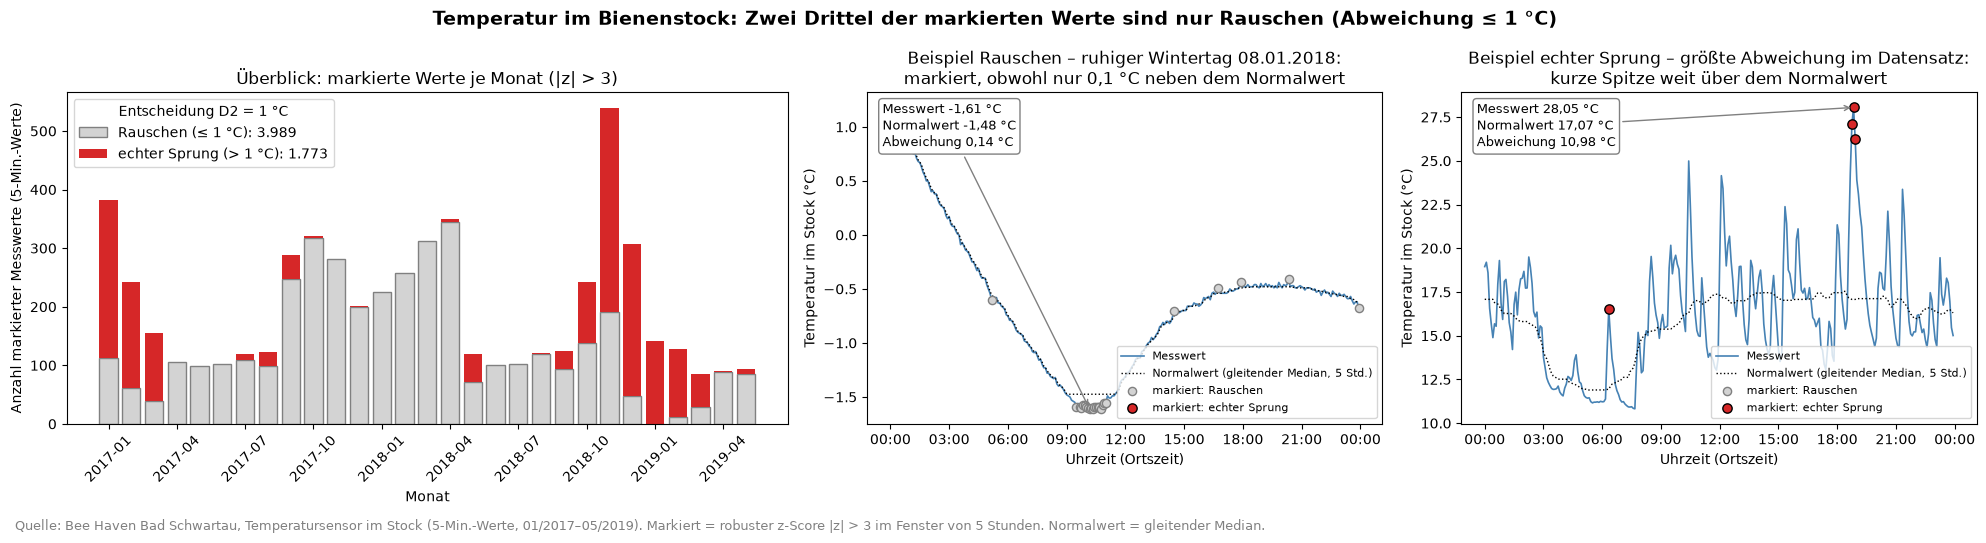

In [12]:
# --- D2 visualisieren (Grafik-Standard: erst Überblick, dann zwei begründete Beispiele) ---
import matplotlib.pyplot as plt                                               # Diagramme
import matplotlib.dates as mdates                                             # Uhrzeit-Format der x-Achse

lokal = te["zeit_utc"].dt.tz_convert(ZEITZONE)                                 # Zeitachse in Ortszeit des Standorts
echt = auff & (abweichung > 1.0)                                              # auffällig UND mehr als 1 °C Abweichung
rauschen = auff & (abweichung <= 1.0)                                         # auffällig, aber höchstens 1 °C Abweichung

fig, ax = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
fig.suptitle("Temperatur im Bienenstock: Zwei Drittel der markierten Werte sind nur Rauschen (Abweichung ≤ 1 °C)",
             fontsize=14, fontweight="bold")

# (1) Überblick: markierte Werte je Monat – Rauschen vs. echte Sprünge
monat = lokal.dt.to_period("M")
uebersicht = pd.DataFrame({"Rauschen (≤ 1 °C)": rauschen.groupby(monat).sum(),
                           "echter Sprung (> 1 °C)": echt.groupby(monat).sum()})
x = range(len(uebersicht))
ax[0].bar(x, uebersicht["Rauschen (≤ 1 °C)"], color="lightgrey", edgecolor="grey", label=f"Rauschen (≤ 1 °C): {int(rauschen.sum()):,}".replace(",", "."))
ax[0].bar(x, uebersicht["echter Sprung (> 1 °C)"], bottom=uebersicht["Rauschen (≤ 1 °C)"], color="tab:red",
          label=f"echter Sprung (> 1 °C): {int(echt.sum()):,}".replace(",", "."))
ax[0].set_xticks(list(x)[::3], [str(p) for p in uebersicht.index][::3], rotation=45)
ax[0].set(title="Überblick: markierte Werte je Monat (|z| > 3)", xlabel="Monat", ylabel="Anzahl markierter Messwerte (5-Min.-Werte)")
ax[0].legend(title="Entscheidung D2 = 1 °C")

# (2) + (3) Beispiele mit Begründung im Titel
beispiele = [(ax[1], "2018-01-08", "Beispiel Rauschen – ruhiger Wintertag 08.01.2018:\nmarkiert, obwohl nur 0,1 °C neben dem Normalwert"),
             (ax[2], str(lokal[abweichung[auff].idxmax()].date()), "Beispiel echter Sprung – größte Abweichung im Datensatz:\nkurze Spitze weit über dem Normalwert")]
for a, datum, titel in beispiele:
    t = lokal.dt.date == pd.Timestamp(datum).date()                            # nur dieser Tag
    a.plot(lokal[t], te.loc[t, "temperature"], color="steelblue", lw=1.2, label="Messwert")
    a.plot(lokal[t], median_te[t], color="black", lw=1, ls=":", label="Normalwert (gleitender Median, 5 Std.)")
    a.scatter(lokal[t & rauschen], te.loc[t & rauschen, "temperature"], color="lightgrey", edgecolors="grey", s=35, zorder=3, label="markiert: Rauschen")
    a.scatter(lokal[t & echt], te.loc[t & echt, "temperature"], color="tab:red", edgecolors="black", s=45, zorder=3, label="markiert: echter Sprung")
    i = abweichung[t & auff].idxmax()                                          # stärkster markierter Punkt des Tages
    text = f"Messwert {te.loc[i, 'temperature']:.2f} °C\nNormalwert {median_te[i]:.2f} °C\nAbweichung {abweichung[i]:.2f} °C"
    a.annotate(text.replace(".", ","),                                         # deutsches Dezimalkomma
               xy=(lokal[i], te.loc[i, "temperature"]), xytext=(0.03, 0.97), textcoords="axes fraction", va="top", fontsize=9,
               bbox=dict(boxstyle="round", fc="white", ec="grey"), arrowprops=dict(arrowstyle="->", color="grey"))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=ZEITZONE))
    a.set(title=titel, xlabel="Uhrzeit (Ortszeit)", ylabel="Temperatur im Stock (°C)")
    a.legend(fontsize=8, loc="lower right")

fig.text(0.01, -0.02, f"Quelle: Bee Haven {ORT['name']}, Temperatursensor im Stock (5-Min.-Werte, 01/2017–05/2019). "
         "Markiert = robuster z-Score |z| > 3 im Fenster von 5 Stunden. Normalwert = gleitender Median.", fontsize=9, color="grey")
plt.tight_layout()
BILDER.mkdir(parents=True, exist_ok=True)                           # Bildordner je Stadt (Regel „Struktur von Anfang an“)
plt.savefig(BILDER / "d2_sensitivitaet_temperatur.png", dpi=120, bbox_inches="tight")
plt.show()

**Ergebnis:** Tabelle und Grafik (gespeichert in `04_images/<stadt>/d2_sensitivitaet_temperatur.png`).

| Kontrollwerte (bleiben auffällig) | 0,5 °C | **1 °C** | 2 °C |
| :-- | --: | --: | --: |
| Schwartau (von 5.762) | 2.624 (45,5 %) | **1.773 (30,8 %)** | 921 (16,0 %) |
| Würzburg (von 37.739) | 25.368 (67,2 %) | **16.590 (44,0 %)** | 10.563 (28,0 %) |

**So liest man die Grafik (Entscheidungsgrundlage Schwartau, 28.09.2026):**
- **Links (Überblick):** Je Monat grau = Rauschen, rot = echter Sprung. Echte Sprünge häufen sich im **Winter (Nov.–März)**, wenn die Stocktemperatur nicht mehr auf ca. 35 °C geregelt wird (Wintertraube) – Hinweis für Warnregel P5. In Schwartau weichen 54 % der Markierungen höchstens 0,5 °C ab → überwiegend Rauschen bzw. Messgenauigkeit.
- **Mitte (ruhiger Wintertag):** Die grauen Punkte liegen auf einer glatten Kurve. Am Tiefpunkt „schneidet“ der gleitende Median die Spitze ab – die Markierungen sind ein Effekt der Methode, keine Ausreißer.
- **Rechts (unruhiger Tag):** Nur deutliche Spitzen werden markiert; große Schwankungen bleiben unmarkiert, wenn die typische Schwankung (MAD) an diesem Tag selbst groß ist.

**Einordnung:** Der z-Score allein ist bei gleichmäßigen Werten zu empfindlich; eine Mindestabweichung trennt Rauschen von echten Sprüngen. **Entscheidung D2 (28.09.2026): 1 °C** – ausgewogen; gilt für alle Standorte, umgesetzt in Kapitel 6d. In Würzburg bleibt ein größerer Anteil auffällig (unruhigerer Temperaturverlauf, 5-Minuten-Takt mit vielen Unregelmäßigkeiten).

## 6d. Entscheidung D2 umsetzen – Mindestabweichung 1 °C für temperature

**Regel (R9, ergänzt):** temperature gilt nur als auffällig, wenn |z| > 3 **und** die Abweichung vom gleitenden Median mehr als 1 °C beträgt.

**Warum?** Sensitivitätsanalyse 6c: 0,5 °C behält viel Rauschen, 2 °C verliert kleinere echte Sprünge; 1 °C ist ausgewogen (Entscheidung nach Prüfung Mensch + KI).

**Kontrollwert:** Anzahl „nachher“ = Zeile 1 °C aus Kapitel 6c

In [13]:
# --- D2: Mindestabweichung 1 °C anwenden (nur temperature) ---
MINDESTABWEICHUNG_C = 1.0                                                     # Entscheidung D2 vom 28.09.2026
vorher = int(te["temperature_auffaellig"].sum())                              # Anzahl vor der Anpassung
te["temperature_auffaellig"] = te["temperature_auffaellig"] & (abweichung > MINDESTABWEICHUNG_C)  # beide Bedingungen
print(f"temperature auffällig: vorher {vorher:,} → nachher {int(te['temperature_auffaellig'].sum()):,}")

temperature auffällig: vorher 5,762 → nachher 1,773


**Ergebnis:** temperature auffällig vorher → nachher in der Ausgabe; die übrigen Markierungen waren Rauschen und sind aufgehoben, die Messwerte bleiben unverändert.

| Kontrollwerte | vorher → nachher |
| :-- | :-- |
| Schwartau | 5.762 → 1.773 |
| Würzburg | 37.739 → 16.590 |

## 7. Speichern nach silver/cleaned

**Wohin?** `cleaned/<stadt>/<sensor>/<sensor>_<stadt>_cleaned__<UTC-Zeitstempel>_UTC.csv` – jeder Lauf erzeugt eine neue Version (Rückgriff auf den letzten guten Stand); `processing` wird nie verändert.

**Kontrollwert:** 4 neue Dateien + Protokoll mit Zeilen und Qualitätsstufen je Sensor

In [14]:
# --- Bereinigte Daten mit UTC-Zeitstempel speichern ---
stempel = datetime.now(timezone.utc).strftime("%Y-%m-%d_%H%M%S")    # aktueller Zeitpunkt in UTC (HH = 24 Stunden)
protokoll = []                                                       # leeres Protokoll
for s in sensoren:                                                   # für jeden Sensor ...
    ordner = CLEANED / s                                             # ... Zielordner cleaned/<stadt>/<sensor>/
    ordner.mkdir(parents=True, exist_ok=True)                        # ... anlegen, falls nicht vorhanden
    ziel = ordner / f"{s}_{STADT}_cleaned__{stempel}_UTC.csv"      # ... Dateiname mit Zeitstempel
    q[s].to_csv(ziel, index=False)                                   # ... als CSV speichern (neue Version, nichts wird überschrieben)
    for alt in sorted(ordner.glob(f"{s}_{STADT}_cleaned__*_UTC.csv")):  # ... ältere Versionen ins _archiv des Ordners (nichts wird gelöscht)
        if alt != ziel:
            (ordner / "_archiv").mkdir(exist_ok=True)
            alt.rename(ordner / "_archiv" / alt.name)
    protokoll.append({"sensor": s, "zeilen": len(q[s]),              # ... Protokollzeile: Zeilen +
                      **q[s]["qualitaet"].value_counts().to_dict()}) #     Anzahl je Qualitätsstufe
    print("gespeichert:", ziel.relative_to(PROJEKT))                 # ... Kontrolle
pd.DataFrame(protokoll).fillna(0)                                    # Protokoll als Tabelle anzeigen

gespeichert: 02_daten_ITS-Data/lakehouse/silver/cleaned/schwartau/flow/flow_schwartau_cleaned__2026-10-01_151930_UTC.csv
gespeichert: 02_daten_ITS-Data/lakehouse/silver/cleaned/schwartau/humidity/humidity_schwartau_cleaned__2026-10-01_151930_UTC.csv


gespeichert: 02_daten_ITS-Data/lakehouse/silver/cleaned/schwartau/temperature/temperature_schwartau_cleaned__2026-10-01_151930_UTC.csv
gespeichert: 02_daten_ITS-Data/lakehouse/silver/cleaned/schwartau/weight/weight_schwartau_cleaned__2026-10-01_151930_UTC.csv


,sensor,zeilen,ok,ungueltig: außerhalb 0–100 %,fehlend,ok: Frost (plausibel),ungueltig: Stock nicht auf Waage (E5)
0,flow,1256918,1256918,0.0,0.0,0.0,0.0
1,humidity,1761,1718,31.0,12.0,0.0,0.0
2,temperature,253430,247365,0.0,2032.0,4033.0,0.0
3,weight,1761,1619,0.0,12.0,0.0,130.0


**Ergebnis:** 4 Dateien in `silver/cleaned/<stadt>/<sensor>/…_cleaned__<UTC-Zeitstempel>_UTC.csv` (neue Version je Lauf). flow hat jetzt eine Zeile je Minute mit `flow_aus` + `flow_ein` (halb so viele Zeilen wie gestapelt).

Hinweis: Die bereinigten CSV sind größer als die Rohdaten, weil `zeit_utc`, `qualitaet` und die `_auffaellig`-Spalten dazukommen – in Azure werden Silver und Gold daher als Parquet gespeichert (Befund Z1).

## Zusammenfassung N2

| Regel | Schwartau | Würzburg |
| :-- | :-- | :-- |
| R5 weight < 20 kg | 102 ungültig | 20.855 ungültig |
| R5a Ausfallzeitraum | 130 Werte (E5, darin alle 102 aus R5) | kein Zeitraum eingetragen |
| R6 humidity außerhalb 0–100 % | 31 ungültig | 6 ungültig |
| R7a temperature außerhalb −40 … 60 °C | 0 | 1 (Fehlerwert) |
| R7 Frost behalten | 4.033 | 23.755 |
| R8 flow getrennt | 1.256.918 Minuten | 1.027.761 Minuten |
| R9 auffällig temperature (D2 > 1 °C) | 1.773 | 16.590 |

Stimmen die Ausgaben mit den Kontrollwerten überein, sind Daten und Regeln unverändert.

**Quellen zu den Erwartungen (Recherche 29.09.2026):**
- [T1] Fahrenholz, Lamprecht, Kraus: „Thermal investigations of a honey bee colony: thermoregulation of the hive during summer and winter“, Journal of Comparative Physiology B (1989): https://link.springer.com/article/10.1007/BF00694379
- [T2] Stabentheiner, Kovac, Brodschneider: „Honeybee Colony Thermoregulation – Regulatory Mechanisms and Contribution of Individuals …“, PLOS ONE (2010): https://www.ncbi.nlm.nih.gov/pmc/articles/PMC2813292/
- [T3] Wikipedia, „Winter cluster“ (Kern ca. 20–30 °C, Rand ca. 12 °C; Übersicht mit Einzelbelegen): https://en.wikipedia.org/wiki/Winter_cluster
- [T4] „Predictive modelling of honey bee foraging activity using local weather conditions“, Apidologie (2018): https://link.springer.com/content/pdf/10.1007/s13592-018-0565-3.pdf
- Statistik: 68-95-99,7-Regel der Normalverteilung (Standardwissen Statistik).

Hinweis: „Kontrollwert“ = Zahl aus Voranalyse oder Vorschritt, die übereinstimmen **muss**; „Erwartung laut Recherche“ = unabhängige Quelle, Abweichungen sind möglich und werden benannt. Auffällige Werte nachts häufiger (E8). Nächster Schritt: N3 Wetter (Bright Sky/DWD + Sonnenstand), danach N4 Gold und N5 Analyse. Lücken werden nicht aufgefüllt (P6 = c, Pflichtenheft Schritt 3.1).